## 读取 Google 股价

In [1]:
import pandas as pd
googl = pd.read_csv('google_stock_prics.csv')
googl.head()

,Date,High,Low,Open,Close,Volume,Adj Close
0,2014-10-06,592.400024,585.400024,589.950012,587.780029,1286100,587.780029
1,2014-10-07,585.849976,574.099976,584.900024,574.099976,1545700,574.099976
2,2014-10-08,584.690002,567.640015,574.789978,583.739990,2207900,583.739990
3,2014-10-09,582.530029,569.030029,581.609985,570.809998,2411700,570.809998
4,2014-10-10,575.229980,555.010010,567.469971,555.190002,2978700,555.190002


## 将数据分为训练与测试数据集

In [2]:
data_length = len(googl)                 # 序列长度
train_size = 0.8                         # 训练集比例
cutoff = round(data_length * train_size) # 序列切分点

# 选择`Open`, `Close` 两列，划分训练集测试集
train = googl.iloc[:cutoff, 3:5]
test = googl.iloc[cutoff:, 3:5]

print("Train shape:", train.shape, "\nTest shape:", test.shape)

Train shape: (1007, 2) 
Test shape: (252, 2)


## 资料标准化

In [3]:
from sklearn.preprocessing import MinMaxScaler

# 训练集极差标准化
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train)

# 测试集标准化用训练集的极差
test_scaled = scaler.transform(test)  

In [4]:
import numpy as np

def process_ts(ts, timesteps=4):
    """
    ts: numpy.array 2D 
    timesteps: 用于预测的序列步长
    returns: `x` with shape [n_samples, timesteps, features]
             `y` with shape [n_samples, features]
    """
    feature_dims = ts.shape[1]
    x, y = [], []
    for i in range(timesteps, len(ts)):
        x.append(ts[i - timesteps: i,])
        y.append(ts[i:i + 1, ])
        
    # 堆叠列表中的array   
    x, y = np.vstack(x), np.vstack(y)  
    # x转换维度为[n_samples, timesteps, features]
    x = x.reshape((-1, timesteps, feature_dims))
    # y转换维度为[samples, features]
    y = y.reshape((-1, feature_dims))
    return x, y

In [5]:
timesteps = 60

train_data, train_target = process_ts(train_scaled, timesteps=timesteps)
test_data, test_target = process_ts(test_scaled, timesteps=timesteps)
print(train_data[:2])
print("-" * 20)
print(train_target[:2])

[[[0.11484026 0.1150627 ]
  [0.1084469  0.09771191]
  [0.09564742 0.1099386 ]
  [0.10428166 0.09353914]
  [0.08638018 0.07372787]
  [0.0707576  0.06048653]
  [0.0644402  0.06548375]
  [0.05423612 0.05538783]
  [0.03514459 0.05055551]
  [0.05217251 0.03286233]
  [0.02685221 0.04479733]
  [0.04814659 0.05196341]
  [0.05293209 0.05787378]
  [0.06208543 0.07177468]
  [0.07056767 0.06575012]
  [0.06142708 0.06699306]
  [0.06642785 0.0784841 ]
  [0.07799917 0.07786263]
  [0.07470756 0.080171  ]
  [0.087431   0.08981025]
  [0.08139216 0.08461014]
  [0.07839163 0.08514282]
  [0.0855193  0.07469181]
  [0.07122602 0.06928873]
  [0.07135259 0.06945362]
  [0.06730141 0.07758356]
  [0.07504941 0.08146464]
  [0.07837904 0.07760895]
  [0.07794856 0.07531328]
  [0.07439106 0.07372787]
  [0.07083356 0.06288369]
  [0.06164228 0.06018215]
  [0.05761636 0.06359395]
  [0.05424879 0.0592309 ]
  [0.06557957 0.06193245]
  [0.05992052 0.06394904]
  [0.06073078 0.06616861]
  [0.06328808 0.06426612]
  [0.0604648

## 建构LSTM神经网路

In [6]:
import tensorflow as tf
print(tf.__version__)

2.19.0


In [7]:
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dropout

feature_dims = train.shape[1]

regressor = Sequential()
regressor.add(LSTM(units=32, return_sequences=True, 
                   input_shape=(timesteps, feature_dims)))
regressor.add(LSTM(units=32, return_sequences=False))
regressor.add(Dropout(0.2))
regressor.add(Dense(units=feature_dims, activation=None))

regressor.summary()

C:\ProgramData\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 60, 32)              │           4,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 2)                   │              66 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,866 (50.26 KB)

 Trainable params: 12,866 (50.26 KB)

 Non-trainable params: 0 (0.00 B)

## 训练LSTM

In [8]:
# 选用MSE损失，adam优化器，编译模型
regressor.compile(optimizer='adam', loss='mean_squared_error')

# 训练
history = regressor.fit(
    train_data,             # 训练集x
    train_target,           # 训练集y
    epochs=100,             # 全量数据训练一次为一个epoch
    batch_size=16,          # 批量梯度下降中的批大小
    validation_data=(test_data, test_target),   # 验证集
    shuffle=False
)

Epoch 1/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 8s 50ms/step - loss: 0.0053 - val_loss: 0.0081
Epoch 2/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.0172 - val_loss: 0.0048
Epoch 3/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0046 - val_loss: 0.0035
Epoch 4/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.0025 - val_loss: 0.0020
Epoch 5/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0025 - val_loss: 0.0063
Epoch 6/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0031 - val_loss: 0.0034
Epoch 7/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - loss: 0.0033 - val_loss: 0.0017
Epoch 8/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.0028 - val_loss: 0.0016
Epoch 9/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0018 - val_loss: 0.0062
Epoch 10/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0026 - val_loss: 0.0036
Epoch 11/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.0021 - val_loss: 0.0015
Epoch 12/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step

## 评估模型在测试数据集的表现

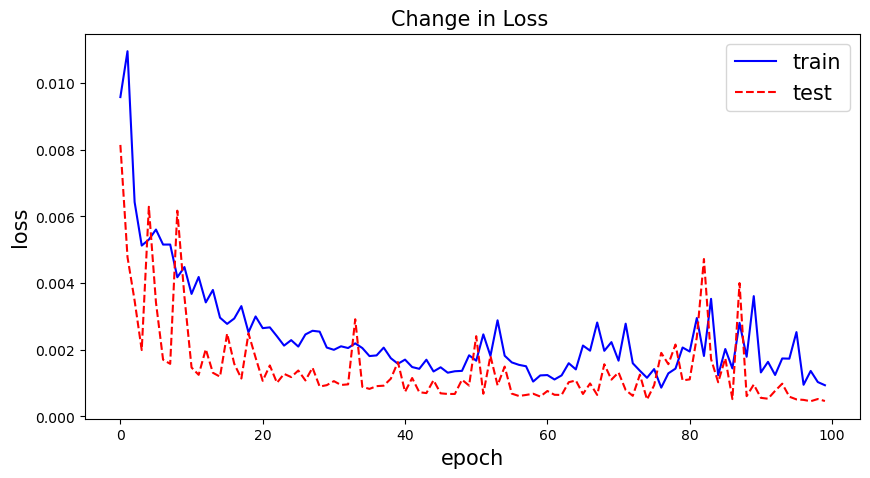

In [9]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=[10, 5])
ax = plt.subplot()
ax.plot(history.history['loss'], 'b-', label='train')
ax.plot(history.history['val_loss'], 'r--', label='test')
# ax.set_yscale('log')   # 纵轴使用对数坐标
plt.title('Change in Loss ', fontsize=15)
plt.ylabel('loss', fontsize=15)
plt.xlabel('epoch', fontsize=15)
plt.legend(fontsize=15)
plt.show()

In [10]:
from sklearn.metrics import mean_absolute_error

# 预测 -> "反标准化"
test_predict = regressor.predict(test_data)
test_predict = scaler.inverse_transform(test_predict)
# 评估平均绝对误差
test_mae = mean_absolute_error(test_predict[:, 0], test.iloc[timesteps:, -1])

# 选定基线模型：使用前一天的收盘价作为第二天收盘价的预测，评估MSE
dummy_mae = mean_absolute_error(test.iloc[timesteps:-1, -1], test.iloc[timesteps + 1:, -1])
print("Mean absolute error : %.2f" %(test_mae))
print("Dummy MSE: %.2f" %(dummy_mae))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
Mean absolute error : 13.15
Dummy MSE: 12.93


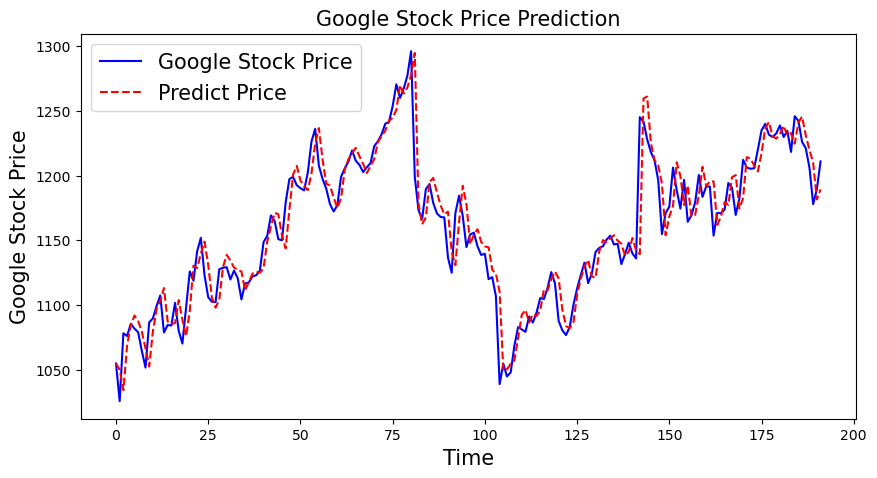

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(test.values[timesteps:, 1], "b-", label='Google Stock Price')
plt.plot(test_predict[:, 0],"r--", label='Predict Price')
plt.title('Google Stock Price Prediction', fontsize=15)
plt.xlabel('Time', fontsize=15)
plt.ylabel('Google Stock Price', fontsize=15)
plt.legend(fontsize=15)
plt.show()